# 4.0 How have trust finances moved over time?

**Board question:** how have NHS trust finances moved, nationally, by sector and by region?

The analysis is done in SQL. Every query lives in
[`sql/analysis/04_sector_trends.sql`](../../sql/analysis/04_sector_trends.sql) and runs against the MySQL warehouse
(`nhs_gold` views and the `nhs_silver.fct_tac` fact table). Each section below shows the query exactly as
it is in that file, then its result.

| Query | SQL technique |
| --- | --- |
| `national_trend` | Aggregate CTE + `LAG()`; weighted margin against the simple mean |
| `sector_kpis_latest_year` | Two-level `WITH ROLLUP` with `GROUPING()` labels |
| `regional_income_growth` | Year-range CTE, two-year pivot, `RANK()` |
| `ebitda_rag_by_sector` | Pivoting a categorical column into counts |
| `income_concentration_latest_year` | `SUM() OVER ()` share and a running `SUM()` window frame |
| `worst_net_margins_latest_year` | `LAG()` over all years, filtered afterwards |
| `drugs_and_negligence_trend` | Two `LAG()` measures over one named window |
| `net_finance_costs` | Signed SoCI lines pivoted from the fact table |

**Data:** NHS England Trust Accounts Consolidation (TAC), annual and actuals only. Money is held in £000s;
columns ending `_m` or `_bn` are converted. Margins are income-weighted (`SUM / SUM`) unless a column says
otherwise. EBITDA in `v_kpis` adds back depreciation, amortisation and impairments. No query is pinned to a
year.

To run it: load the warehouse, `export DB_PASSWORD=...`, then run all cells.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Make analysis/nhs_analysis.py importable from the repo root or from this folder
here = Path.cwd()
sys.path.insert(0, str(here.parent if here.name == "notebooks" else here / "analysis"))
import nhs_analysis as nhs

nhs.set_style()
pd.options.display.float_format = "{:,.1f}".format
pd.options.display.max_columns = 20

## 4.1 The national picture

Aggregated per year in a CTE, then `LAG()` reads the previous year's income for the growth rate. The
income-weighted EBITDA margin (total EBITDA ÷ total income) sits next to the simple mean across trusts: if
the two differ, large trusts are doing better or worse than small ones.

In [2]:
national = nhs.sql("04_sector_trends", "national_trend")
national

`sql/analysis/04_sector_trends.sql` → **national_trend**

```sql
-- The national picture each year: income, costs, results and margins, with
-- income growth on the year before.
-- Technique: aggregate per year in a CTE, then LAG() for growth; an
-- income-weighted margin next to the simple average across trusts, which
-- shows how much large trusts pull the national figure.
WITH yearly AS (
    SELECT
        financial_year,
        COUNT(*)                     AS trusts,
        SUM(operating_surplus_000s < 0) AS trusts_in_deficit,
        SUM(total_income_000s)       AS income_000s,
        SUM(total_expenditure_000s)  AS expenditure_000s,
        SUM(operating_surplus_000s)  AS operating_surplus_000s,
        SUM(net_surplus_000s)        AS net_surplus_000s,
        SUM(ebitda_000s)             AS ebitda_000s,
        AVG(ebitda_margin_pct)       AS mean_trust_ebitda_pct
    FROM v_kpis
    GROUP BY financial_year
)
SELECT
    financial_year,
    trusts,
    trusts_in_deficit,
    ROUND(income_000s / 1e6, 2)                                              AS income_bn,
    ROUND(100 * (income_000s / LAG(income_000s) OVER (ORDER BY financial_year) - 1), 1)
                                                                             AS income_growth_pct,
    ROUND(expenditure_000s / 1e6, 2)                                         AS expenditure_bn,
    ROUND(operating_surplus_000s / 1000, 1)                                  AS operating_surplus_m,
    ROUND(net_surplus_000s / 1000, 1)                                        AS net_surplus_m,
    ROUND(100 * ebitda_000s / income_000s, 2)                                AS weighted_ebitda_margin_pct,
    ROUND(mean_trust_ebitda_pct, 2)                                          AS mean_trust_ebitda_margin_pct
FROM yearly
ORDER BY financial_year;
```

,financial_year,trusts,trusts_in_deficit,income_bn,income_growth_pct,expenditure_bn,operating_surplus_m,net_surplus_m,weighted_ebitda_margin_pct,mean_trust_ebitda_margin_pct
0,2021/22,215,38,115.6,NaN,113.9,"1,690.1",476.6,4.7,4.5
1,2022/23,212,87,124.4,7.7,124.2,210.7,"-1,398.9",4.3,4.3
2,2023/24,206,124,129.2,3.8,130.8,"-1,634.3","-4,295.2",3.7,3.6


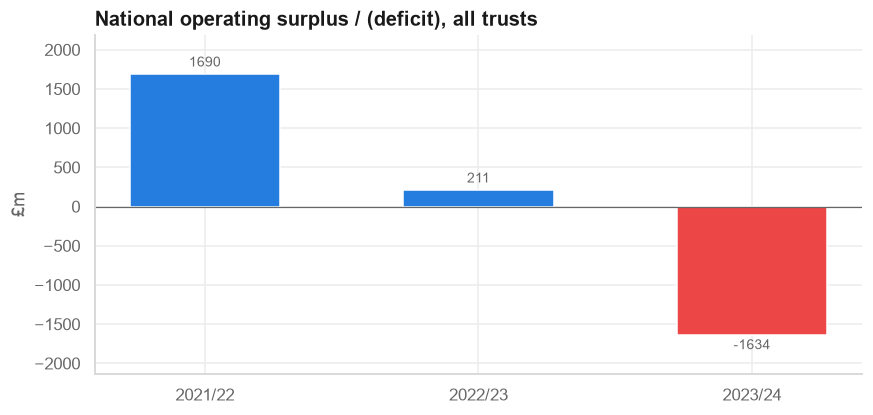

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
colours = [nhs.DEFICIT if v < 0 else nhs.SURPLUS for v in national.operating_surplus_m]
bars = ax.bar(national.financial_year, national.operating_surplus_m, color=colours, width=0.55)
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9, color=nhs.TEXT_SECONDARY)
ax.axhline(0, color=nhs.TEXT_SECONDARY, linewidth=0.8)
ax.margins(y=0.15)
ax.set(title="National operating surplus / (deficit), all trusts", ylabel="£m", xlabel=None)
plt.show()

## 4.2 Sectors in the latest year, by trust type

`GROUP BY sector, trust_type WITH ROLLUP` produces three levels in one pass: each sector and trust type,
a subtotal per sector, and a national total. `GROUPING()` labels the generated rows.

In [4]:
nhs.sql("04_sector_trends", "sector_kpis_latest_year")

`sql/analysis/04_sector_trends.sql` → **sector_kpis_latest_year**

```sql
-- Each sector in the latest year, split by NHS trust and foundation trust, with
-- a subtotal per sector and a national total.
-- Technique: GROUP BY sector, trust_type WITH ROLLUP; GROUPING() labels the
-- subtotal and total rows; the deficit of deficit trusts only, by conditional SUM.
SELECT
    IF(GROUPING(sector) = 1, 'All sectors', sector)                         AS sector,
    IF(GROUPING(trust_type) = 1, 'All', trust_type)                         AS trust_type,
    COUNT(*)                                                                AS trusts,
    ROUND(SUM(total_income_000s) / 1000, 1)                                 AS income_m,
    ROUND(100 * SUM(ebitda_000s) / SUM(total_income_000s), 2)              AS ebitda_margin_pct,
    ROUND(100 * SUM(pay_000s) / SUM(total_income_000s), 1)                 AS pay_pct_income,
    ROUND(100 * SUM(net_surplus_000s) / SUM(total_income_000s), 2)         AS net_margin_pct,
    SUM(operating_surplus_000s < 0)                                         AS trusts_in_deficit,
    ROUND(SUM(CASE WHEN operating_surplus_000s < 0
                   THEN operating_surplus_000s ELSE 0 END) / 1000, 1)       AS deficit_of_deficit_trusts_m
FROM v_kpis
WHERE financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
GROUP BY sector, trust_type WITH ROLLUP
ORDER BY GROUPING(sector), sector, GROUPING(trust_type), trust_type;
```

,sector,trust_type,trusts,income_m,ebitda_margin_pct,pay_pct_income,net_margin_pct,trusts_in_deficit,deficit_of_deficit_trusts_m
0,Acute,FOUNDATION_TRUST,78,"65,848.1",3.4,62.7,-3.7,52,"-1,556.0"
1,Acute,NHS_TRUST,40,"32,167.6",4.0,63.5,-3.8,22,-375.4
2,Acute,All,118,"98,015.7",3.6,63.0,-3.7,74,"-1,931.4"
3,Ambulance,FOUNDATION_TRUST,5,"1,718.4",3.9,70.0,-2.4,4,-48.9
4,Ambulance,NHS_TRUST,5,"2,348.8",4.8,71.9,0.1,4,-2.6
5,Ambulance,All,10,"4,067.1",4.4,71.1,-1.0,8,-51.5
6,Community,FOUNDATION_TRUST,8,"2,107.7",4.8,72.8,-0.7,4,-23.6
7,Community,NHS_TRUST,10,"2,095.5",5.0,70.2,-0.4,4,-17.8
8,Community,All,18,"4,203.2",4.9,71.5,-0.5,8,-41.4
9,Mental Health,FOUNDATION_TRUST,35,"15,100.6",3.3,70.2,-2.2,23,-271.1


## 4.3 Income growth by region

The year range comes from a one-row CTE, so the query never names a year; conditional aggregation turns
the first and latest years into columns, and `RANK()` orders the regions.

In [5]:
nhs.sql("04_sector_trends", "regional_income_growth")

`sql/analysis/04_sector_trends.sql` → **regional_income_growth**

```sql
-- Income growth in each NHS England region between the first and latest year,
-- ranked.
-- Technique: a one-row CTE holding the year range, a two-year pivot with
-- conditional aggregation, then RANK() on the growth.
WITH yrs AS (
    SELECT MIN(financial_year) AS first_year, MAX(financial_year) AS latest_year
    FROM nhs_silver.fct_tac
),
pivoted AS (
    SELECT
        k.region,
        SUM(CASE WHEN k.financial_year = y.first_year  THEN k.total_income_000s END) AS income_first,
        SUM(CASE WHEN k.financial_year = y.latest_year THEN k.total_income_000s END) AS income_latest,
        SUM(CASE WHEN k.financial_year = y.first_year  THEN k.operating_surplus_000s END) AS result_first,
        SUM(CASE WHEN k.financial_year = y.latest_year THEN k.operating_surplus_000s END) AS result_latest
    FROM v_kpis k
    CROSS JOIN yrs y
    WHERE k.region IS NOT NULL
    GROUP BY k.region
)
SELECT
    RANK() OVER (ORDER BY income_latest / income_first DESC)     AS growth_rank,
    region,
    ROUND(income_first / 1000, 1)                                AS income_first_year_m,
    ROUND(income_latest / 1000, 1)                               AS income_latest_year_m,
    ROUND(100 * (income_latest / income_first - 1), 1)           AS income_growth_pct,
    ROUND((result_latest - result_first) / 1000, 1)              AS change_in_operating_result_m
FROM pivoted
ORDER BY growth_rank;
```

,growth_rank,region,income_first_year_m,income_latest_year_m,income_growth_pct,change_in_operating_result_m
0,1,South West,"10,504.4","12,294.8",17.0,-238.3
1,2,East of England,"10,990.5","12,596.5",14.6,-249.6
2,3,South East,"15,689.3","17,824.3",13.6,-667.9
3,4,Midlands,"20,131.2","22,855.2",13.5,-410.1
4,5,North East and Yorkshire,"17,252.6","19,349.9",12.2,-410.2
5,6,North West,"16,321.8","18,152.2",11.2,-588.4
6,7,London,"24,672.6","26,133.1",5.9,-759.9


## 4.4 EBITDA bands by sector

Rather than re-typing the band thresholds, this pivots `v_kpis`'s own `ebitda_rag` column (Green 5% or
more, Amber 2–5%, Red below 2%) into one count column per band, so the bands are defined in one place.

In [6]:
nhs.sql("04_sector_trends", "ebitda_rag_by_sector")

`sql/analysis/04_sector_trends.sql` → **ebitda_rag_by_sector**

```sql
-- How many trusts in each sector fall in each EBITDA band in the latest year,
-- using the same Green / Amber / Red bands as v_kpis (>= 5%, 2-5%, < 2%).
-- Technique: pivot a categorical column (ebitda_rag) into one column per value,
-- reusing the view's own banding rather than re-typing the thresholds.
SELECT
    sector,
    COUNT(*)                                                        AS trusts,
    SUM(ebitda_rag = 'Green')                                       AS green_5pct_plus,
    SUM(ebitda_rag = 'Amber')                                       AS amber_2_to_5pct,
    SUM(ebitda_rag = 'Red')                                         AS red_below_2pct,
    SUM(ebitda_rag = 'Not assessed')                                AS not_assessed,
    ROUND(100 * AVG(ebitda_rag = 'Red'), 1)                         AS pct_red
FROM v_kpis
WHERE financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
GROUP BY sector
ORDER BY pct_red DESC;
```

,sector,trusts,green_5pct_plus,amber_2_to_5pct,red_below_2pct,not_assessed,pct_red
0,Acute,118,29,60,29,0,24.6
1,Mental Health,45,6,31,8,0,17.8
2,Specialist,15,9,4,2,0,13.3
3,Ambulance,10,4,5,1,0,10.0
4,Community,18,10,8,0,0,0.0


## 4.5 How concentrated is trust income?

`SUM() OVER ()` puts national income on every row for each trust's share; a running sum with an explicit
`ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW` frame gives the cumulative share down the ranking.

In [7]:
nhs.sql("04_sector_trends", "income_concentration_latest_year")

`sql/analysis/04_sector_trends.sql` → **income_concentration_latest_year**

```sql
-- The twenty largest trusts by income in the latest year, each one's share of
-- national income, and the running share: how concentrated NHS trust income is.
-- Technique: SUM() OVER () for the national total, a running SUM() OVER
-- (ORDER BY ...) for the cumulative share, and DENSE_RANK().
WITH latest AS (
    SELECT organisation_name, sector, total_income_000s, operating_surplus_000s, ebitda_margin_pct
    FROM v_kpis
    WHERE financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
),
shares AS (
    SELECT
        l.*,
        DENSE_RANK() OVER (ORDER BY total_income_000s DESC)                          AS income_rank,
        100 * total_income_000s / SUM(total_income_000s) OVER ()                     AS share_pct,
        100 * SUM(total_income_000s) OVER (ORDER BY total_income_000s DESC
                                           ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
            / SUM(total_income_000s) OVER ()                                         AS cumulative_share_pct
    FROM latest l
)
SELECT
    income_rank,
    organisation_name,
    sector,
    ROUND(total_income_000s / 1000, 1)       AS income_m,
    ROUND(share_pct, 2)                      AS share_of_national_pct,
    ROUND(cumulative_share_pct, 1)           AS cumulative_share_pct,
    ROUND(operating_surplus_000s / 1000, 1)  AS operating_surplus_m,
    ebitda_margin_pct
FROM shares
WHERE income_rank <= 20
ORDER BY income_rank;
```

,income_rank,organisation_name,sector,income_m,share_of_national_pct,cumulative_share_pct,operating_surplus_m,ebitda_margin_pct
0,1,Guy's & St Thomas' NHS Foundation Trust,Acute,"2,891.7",2.2,2.2,-66.4,4.9
1,2,Manchester University NHS Foundation Trust,Acute,"2,814.1",2.2,4.4,11.3,4.0
2,3,University Hospitals Birmingham NHS Foundation...,Acute,"2,423.1",1.9,6.3,15.9,2.8
3,4,Barts Health NHS Trust,Acute,"2,394.9",1.9,8.1,22.8,5.3
4,5,The Leeds Teaching Hospitals NHS Trust,Acute,"1,900.5",1.5,9.6,43.0,4.3
5,6,King’s College Hospital NHS Foundation Trust,Acute,"1,796.0",1.4,11.0,-52.9,1.4
6,7,Northern Care Alliance NHS Foundation Trust,Acute,"1,784.2",1.4,12.4,-85.0,0.4
7,8,Imperial College Healthcare NHS Trust,Acute,"1,714.7",1.3,13.7,-10.0,4.9
8,9,University College London Hospitals NHS Founda...,Acute,"1,680.7",1.3,15.0,74.7,8.6
9,10,Nottingham University Hospitals NHS Trust,Acute,"1,677.2",1.3,16.3,-64.9,0.4


## 4.6 The weakest net margins, and whether they are getting worse

`LAG()` runs over every year first and the latest year is filtered afterwards. Filtering in the same
query level first would leave `LAG()` with no prior year to read.

In [8]:
nhs.sql("04_sector_trends", "worst_net_margins_latest_year")

`sql/analysis/04_sector_trends.sql` → **worst_net_margins_latest_year**

```sql
-- The twenty trusts with the lowest net surplus margin in the latest year, and
-- whether each one is getting worse: its margin the year before alongside.
-- Technique: LAG() computed over every year first, then filtered to the latest
-- year (filtering first would leave LAG nothing to look back at).
WITH margins AS (
    SELECT
        organisation_name, sector, trust_type, financial_year,
        total_income_000s, net_surplus_000s, net_surplus_margin_pct, ebitda_margin_pct,
        LAG(net_surplus_margin_pct) OVER (PARTITION BY org_code ORDER BY financial_year) AS prior_net_margin_pct
    FROM v_kpis
)
SELECT
    RANK() OVER (ORDER BY net_surplus_margin_pct)                AS worst_rank,
    organisation_name,
    sector,
    trust_type,
    ROUND(total_income_000s / 1000, 1)                           AS income_m,
    ROUND(net_surplus_000s / 1000, 1)                            AS net_surplus_m,
    net_surplus_margin_pct,
    prior_net_margin_pct,
    ROUND(net_surplus_margin_pct - prior_net_margin_pct, 1)     AS change_pts,
    ebitda_margin_pct
FROM margins
WHERE financial_year = (SELECT MAX(financial_year) FROM nhs_silver.fct_tac)
ORDER BY worst_rank
LIMIT 20;
```

,worst_rank,organisation_name,sector,trust_type,income_m,net_surplus_m,net_surplus_margin_pct,prior_net_margin_pct,change_pts,ebitda_margin_pct
0,1,Southport And Ormskirk Hospital NHS Trust,Acute,NHS_TRUST,67.1,-118.8,-177.1,-6.8,-170.3,1.8
1,2,West Suffolk NHS Foundation Trust,Acute,FOUNDATION_TRUST,397.3,-96.3,-24.2,0.1,-24.3,3.4
2,3,East Kent Hospitals University NHS Foundation ...,Acute,FOUNDATION_TRUST,939.6,-153.0,-16.3,-4.2,-12.1,-9.1
3,4,Mid Cheshire Hospitals NHS Foundation Trust,Acute,FOUNDATION_TRUST,399.9,-60.3,-15.1,-6.3,-8.8,-2.2
4,4,Liverpool Women's NHS Foundation Trust,Specialist,FOUNDATION_TRUST,149.3,-22.6,-15.1,-1.7,-13.4,-9.2
5,6,South West London and St George's Mental Healt...,Mental Health,NHS_TRUST,316.5,-47.2,-14.9,-1.1,-13.8,3.6
6,7,Doncaster and Bassetlaw Teaching Hospitals NHS...,Acute,FOUNDATION_TRUST,561.3,-72.1,-12.8,-3.4,-9.4,-0.8
7,8,The Christie NHS Foundation Trust,Specialist,FOUNDATION_TRUST,472.2,-59.3,-12.6,2.8,-15.4,4.9
8,9,Tameside and Glossop Integrated Care NHS Found...,Acute,FOUNDATION_TRUST,315.1,-38.8,-12.3,-1.0,-11.3,-3.2
9,10,University Hospitals Sussex NHS Foundation Trust,Acute,FOUNDATION_TRUST,"1,524.4",-178.7,-11.7,-4.2,-7.5,4.0


## 4.7 Drugs and clinical negligence

Two costs a trust controls only partly. Both growth rates come from `LAG()` over a single named window.

In [9]:
nhs.sql("04_sector_trends", "drugs_and_negligence_trend")

`sql/analysis/04_sector_trends.sql` → **drugs_and_negligence_trend**

```sql
-- Two cost lines outside a trust's direct control: drugs, and the clinical
-- negligence premium paid to NHS Resolution, as a share of income by sector
-- and year, with the year-on-year movement.
-- Technique: weighted shares per group, then LAG() over each sector's years
-- for two measures in the same window.
WITH sector_year AS (
    SELECT
        sector,
        financial_year,
        SUM(drugs_cost_000s)          AS drugs_000s,
        SUM(clinical_negligence_000s) AS negligence_000s,
        SUM(total_income_000s)        AS income_000s
    FROM v_kpis
    GROUP BY sector, financial_year
)
SELECT
    sector,
    financial_year,
    ROUND(drugs_000s / 1000, 1)                                         AS drugs_m,
    ROUND(100 * drugs_000s / income_000s, 2)                            AS drugs_pct_income,
    ROUND(100 * (drugs_000s / LAG(drugs_000s) OVER w - 1), 1)           AS drugs_growth_pct,
    ROUND(negligence_000s / 1000, 1)                                    AS negligence_m,
    ROUND(100 * negligence_000s / income_000s, 2)                       AS negligence_pct_income,
    ROUND(100 * (negligence_000s / LAG(negligence_000s) OVER w - 1), 1) AS negligence_growth_pct
FROM sector_year
WINDOW w AS (PARTITION BY sector ORDER BY financial_year)
ORDER BY sector, financial_year;
```

,sector,financial_year,drugs_m,drugs_pct_income,drugs_growth_pct,negligence_m,negligence_pct_income,negligence_growth_pct
0,Acute,2021/22,"8,344.1",9.6,NaN,"2,290.6",2.6,NaN
1,Acute,2022/23,"9,044.3",9.7,8.4,"2,267.1",2.4,-1.0
2,Acute,2023/24,"9,697.1",9.9,7.2,"2,404.6",2.5,6.1
3,Ambulance,2021/22,8.4,0.2,NaN,27.8,0.8,NaN
4,Ambulance,2022/23,9.7,0.2,16.0,26.8,0.7,-3.5
5,Ambulance,2023/24,9.5,0.2,-2.5,30.3,0.7,12.9
6,Community,2021/22,60.9,1.6,NaN,11.7,0.3,NaN
7,Community,2022/23,59.9,1.5,-1.7,13.0,0.3,10.7
8,Community,2023/24,67.0,1.6,11.9,14.7,0.3,13.0
9,Mental Health,2021/22,243.6,1.5,NaN,50.2,0.3,NaN


## 4.8 Net finance costs

Interest received, interest paid and the PDC dividend, pivoted from the SoCI lines in the fact table. The
SoCI stores costs as negative values, so the net cost is the plain sum of the three lines.

In [10]:
nhs.sql("04_sector_trends", "net_finance_costs")

`sql/analysis/04_sector_trends.sql` → **net_finance_costs**

```sql
-- What trusts pay to finance themselves each year: interest received, interest
-- paid, and the public dividend capital (PDC) dividend paid to government.
-- These lines sit below the operating result in the SoCI, which stores costs
-- as negative values, so the net cost is the plain sum of the three.
-- Technique: pivot three SubCodes out of the long fact table in one pass.
SELECT
    financial_year,
    ROUND(SUM(CASE WHEN sub_code = 'SCI0150' THEN total_000s ELSE 0 END) / 1000, 1) AS finance_income_m,
    ROUND(SUM(CASE WHEN sub_code = 'SCI0160' THEN total_000s ELSE 0 END) / 1000, 1) AS finance_expense_m,
    ROUND(SUM(CASE WHEN sub_code = 'SCI0170' THEN total_000s ELSE 0 END) / 1000, 1) AS pdc_dividend_m,
    ROUND(SUM(total_000s) / 1000, 1)                                                 AS net_finance_cost_m,
    COUNT(DISTINCT org_code)                                                         AS trusts_reporting
FROM nhs_silver.fct_tac
WHERE worksheet_name = 'TAC02 SoCI'
  AND sub_code IN ('SCI0150', 'SCI0160', 'SCI0170')
GROUP BY financial_year
ORDER BY financial_year;
```

,financial_year,finance_income_m,finance_expense_m,pdc_dividend_m,net_finance_cost_m,trusts_reporting
0,2021/22,16.9,-906.4,-904.3,"-1,793.8",215
1,2022/23,311.7,"-1,007.5","-1,040.9","-1,736.8",212
2,2023/24,653.8,"-2,386.4","-1,010.5","-2,743.1",206
